# Carteras de bajo incumplimiento: la estimación más prudente de Pluto y Tasche

**Pregunta:** ¿Qué PD puede defender una cartera de bajo incumplimiento para cada grado cuando su mejor grado no muestra ningún incumplimiento, cuánto la sube la correlación de incumplimientos y cuánto capital agrega la prudencia a las cifras de un experto?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 02 de este tema (intervalos sobre un grado delgado)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar la estimación más prudente: una PD para cada grado como cota superior de confianza, bajo el supuesto de que todo grado peor tiene la misma PD, y decir por qué necesita conteos agrupados;
- calcular la cota para incumplimientos independientes y leerla frente a la forma cerrada para cero incumplimientos y frente al cuantil Beta de SciPy;
- agregar correlación de incumplimientos con el modelo de un factor, y leer cuánto sube la cota;
- escalar las cotas a una meta de la cartera, y llevar una cohorte de varios años con factores serialmente correlacionados;
- recalcular las 204 celdas impresas de las Tablas 1 a 14 de Pluto y Tasche, listar las celdas que se desvían y decir por qué;
- leer lo que dice un estudio de verdad conocida sobre la cobertura, y cuánto cuestan las cotas en capital.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.engines import low_default as ld
from riskvalidation.regulatory import irb
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados del caso C05, la segunda mitad del caso: carteras de bajo incumplimiento (clase de licencia `derived-only` para las tablas impresas de Pluto y Tasche, 2005; https://arxiv.org/abs/cond-mat/0411699):

- `data/derived/C05/ldp-published.json`: el ejemplo del artículo, tres grados A, B y C con 100, 400 y 300 deudores y 0, 2 y 1 incumplimientos, las cotas a seis niveles de confianza, las 204 celdas impresas de las Tablas 1 a 14 con el recálculo (`outputs.golden`), las pruebas versionadas de las PD de un experto hipotético, y el impacto en capital.
- `data/derived/C05/ldp-sim-0.json`, `ldp-sim-1.json` y `ldp-sim-3.json`: la misma cartera en un año generado por un modelo de Vasicek con PD conocidas (0,05%, 0,10% y 0,20%, correlación 12%) con ningún incumplimiento, uno y tres, cada uno con la cobertura de las cotas y el tamaño y la potencia de las pruebas medidos en 20.000 años generados.

Los conteos por grado son el ejemplo del propio artículo, público en él.

La celda siguiente carga los archivos e imprime el ejemplo.

In [2]:
# Cargar los cuatro artefactos (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
C05 = ROOT / "data" / "derived" / "C05"
load = lambda name: json.loads((C05 / name).read_text(encoding="utf-8"))
published = load("ldp-published.json")
sims = {k: load(f"ldp-sim-{k}.json") for k in (0, 1, 3)}
out = published["outputs"]
grades, N, few = out["grades"], tuple(out["obligors"]), tuple(out["defaults"])
gammas, rho = out["gammas"], out["rho"]

print("grados:", grades, "| deudores:", N, "| incumplimientos:", few)
print("niveles de confianza:", gammas, "| correlación de activos del artículo:", rho)
print("PD hipotéticas del experto:", out["expert_pd"])

grados: ['A', 'B', 'C'] | deudores: (100, 400, 300) | incumplimientos: (0, 2, 1)
niveles de confianza: [0.5, 0.75, 0.9, 0.95, 0.99, 0.999] | correlación de activos del artículo: 0.12
PD hipotéticas del experto: [0.0003, 0.0005, 0.001]


## Método

### Paso 1: la estimación más prudente, incumplimientos independientes

Con tres incumplimientos en 800 deudores una cartera tiene una tasa de incumplimiento, pero los grados individuales no: A no tiene ninguno. Pluto y Tasche (2005) piden la PD de cada grado como **cota superior de confianza** al nivel $\gamma$, bajo el supuesto *más prudente* compatible con el orden de los grados: todo grado desde $i$ hacia abajo tiene la misma PD, así que se agrupan los deudores y los incumplimientos de los grados $i, \dots, k$. Con $N$ deudores agrupados y $D$ incumplimientos agrupados, incumplimientos independientes, la cota $p$ resuelve

$$P\bigl(\mathrm{Binomial}(N, p) \le D\bigr) = 1 - \gamma$$

(la cota superior de Clopper-Pearson). Para $D = 0$ tiene la forma cerrada $p = 1 - (1 - \gamma)^{1/N}$. El `most_prudent_pd` del motor devuelve las cotas y los conteos agrupados. Hay dos verificaciones independientes: la forma cerrada para un caso sin incumplimientos, y el cuantil de la distribución Beta de SciPy, pues la cola binomial y la función de distribución Beta son la misma función.

La celda siguiente imprime los conteos agrupados y las cotas al 90%, con el cuantil Beta de SciPy junto a la cota del motor, y el caso de cero incumplimientos junto a su forma cerrada.

In [3]:
# Las cotas del ejemplo al 90%, el cuantil Beta de SciPy y la forma cerrada para cero incumplimientos
gamma = 0.9
bound = ld.most_prudent_pd(N, few, gamma)
pooled_n, pooled_d = bound["pooled_obligors"], bound["pooled_defaults"]
beta = [stats.beta.ppf(gamma, d + 1, n - d) for n, d in zip(pooled_n, pooled_d)]
zero = ld.most_prudent_pd(N, (0, 0, 0), gamma)
closed = [1 - (1 - gamma) ** (1 / n) for n in zero["pooled_obligors"]]

print(f"{'grado':8s}{'N agrupado':>14s}{'D agrupado':>14s}{'motor':>12s}{'Beta':>10s}")
for g in range(3):
    print(f"{grades[g]:8s}{pooled_n[g]:14d}{pooled_d[g]:14d}{100 * bound['pd'][g]:11.4f}%{100 * beta[g]:9.4f}%")
print("cero incumplimientos, motor:", [f"{100 * p:.4f}%" for p in zero["pd"]])
print("cero incumplimientos, forma cerrada:", [f"{100 * p:.4f}%" for p in closed])

grado       N agrupado    D agrupado       motor      Beta
A                  800             3     0.8332%   0.8332%
B                  700             3     0.9519%   0.9519%
C                  300             1     1.2903%   1.2903%
cero incumplimientos, motor: ['0.2874%', '0.3284%', '0.7646%']
cero incumplimientos, forma cerrada: ['0.2874%', '0.3284%', '0.7646%']


Las cotas suben de A a C, como lo garantiza la construcción, y todo grado, incluso A sin incumplimientos, recibe una PD positiva que descansa en los 800 deudores: 0,8332% para A, 0,9519% para B y 1,2903% para C al 90%. La cota del motor y el cuantil Beta de SciPy son el mismo número, porque la cola binomial y la función de distribución Beta son la misma función, y sin incumplimientos el motor iguala la forma cerrada. El costo es el conservadurismo: las cotas dicen cuán alta puede ser la PD con esa confianza, no cuál es probablemente. Los números aún no reflejan que los deudores caen en incumplimiento juntos, que es el paso siguiente.

### Paso 2: correlación de incumplimientos

Los incumplimientos de deudores que comparten una economía están correlacionados, y la ley binomial subestima entonces la dispersión del número de incumplimientos. Pluto y Tasche (sección 4) usan el modelo de un factor: cada deudor cae en incumplimiento cuando $\sqrt{\rho}\,Y + \sqrt{1-\rho}\,\xi$ queda bajo $\Phi^{-1}(p)$, con un factor común $Y$, así que dado $Y = y$ la probabilidad de incumplimiento es $p(y) = \Phi\bigl((\Phi^{-1}(p) - \sqrt{\rho}\,y)/\sqrt{1-\rho}\bigr)$ y la cota resuelve

$$1 - \gamma = \int \varphi(y)\, P\bigl(\mathrm{Binomial}(N, p(y)) \le D\bigr)\, dy$$

El motor integra por cuadratura de Gauss-Hermite. El artículo toma $\rho = 12\%$, la correlación corporativa mínima de Basilea (CRE31).

La celda siguiente calcula las cotas independientes y las correlacionadas en los seis niveles e imprime cuántas veces más altas son las correlacionadas.

In [4]:
# Las cotas independientes y correlacionadas en los seis niveles, y su razón
independent = np.array([ld.most_prudent_pd(N, few, g)["pd"] for g in gammas])
correlated = np.array([ld.most_prudent_pd(N, few, g, rho)["pd"] for g in gammas])

head = "".join(f"{g + ' (%)':>12s}" for g in grades) + "".join(f"{g + ' razón':>12s}" for g in grades)
print(f"{'nivel':>7s}" + head)
for gm, c, i in zip(gammas, correlated, independent):
    print(f"{gm:7.3f}" + "".join(f"{100 * v:11.4f}%" for v in c) + "".join(f"{v:12.2f}" for v in c / i))

  nivel       A (%)       B (%)       C (%)     A razón     B razón     C razón
  0.500     0.7106%     0.8006%     0.8352%        1.55        1.53        1.49
  0.750     1.4149%     1.5808%     1.7536%        2.22        2.17        1.96
  0.900     2.4910%     2.7617%     3.1813%        2.99        2.90        2.47
  0.950     3.4121%     3.7653%     4.4078%        3.53        3.41        2.80
  0.990     5.8758%     6.4272%     7.6714%        4.70        4.50        3.50
  0.999    10.0754%    10.9121%    13.1333%        6.21        5.89        4.33


La celda siguiente dibuja las cotas independientes (continuas) y las correlacionadas (punteadas) de los tres grados contra el nivel de confianza, con las PD del experto como líneas de puntos.

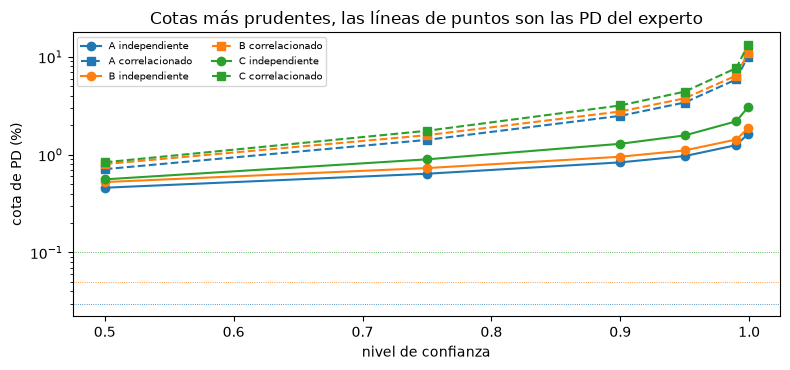

In [5]:
# Dibujar las cotas independientes y correlacionadas contra el nivel de confianza, con las PD del experto
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, color in enumerate(("tab:blue", "tab:orange", "tab:green")):
    ax.plot(gammas, 100 * independent[:, j], color=color, marker="o", label=f"{grades[j]} independiente")
    ax.plot(gammas, 100 * correlated[:, j], color=color, marker="s", linestyle="--",
            label=f"{grades[j]} correlacionado")
    ax.axhline(100 * out["expert_pd"][j], color=color, linewidth=0.6, linestyle=":")
ax.set_yscale("log")
ax.set_xlabel("nivel de confianza")
ax.set_ylabel("cota de PD (%)")
ax.set_title("Cotas más prudentes, las líneas de puntos son las PD del experto")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

Con la correlación de activos del artículo de 12% las cotas al 90% son 2,4910%, 2,7617% y 3,1813%, cerca de tres veces las independientes para A y B y 2,5 veces para C, y al 99,9% la cota de A es 10,0754%, 6,2 veces su cota independiente. Las líneas correlacionadas quedan muy sobre las independientes con confianza alta y cerca de 1,5 veces sobre ellas al 50%, así que el nivel de confianza y la correlación trabajan juntos. Las tres PD del experto quedan bajo toda cota dibujada, por un factor de 13 a 28 frente a las cotas independientes al 90%, que es el sentido en que las cifras del experto no son prudentes; que estén equivocadas es una pregunta estadística que el Paso 7 plantea a los datos. La figura no elige el nivel de confianza: el artículo llama arbitraria la elección y encuentra más apropiados los niveles bajo 95%.

### Paso 3: escalar a una meta de la cartera

Las cotas de los tres grados son todas cotas superiores: su promedio ponderado queda muy por sobre la tasa de incumplimiento propia de la cartera. La sección 5 del artículo las escala con un factor común $K$, manteniendo su orden y sus razones, de modo que el promedio ponderado por deudores iguale una meta $T$:

$$K = \frac{T \sum_i n_i}{\sum_i n_i\, \hat p_i}, \qquad p_i^{\mathrm{escalada}} = K\, \hat p_i$$

(ecuaciones 5.1 y 5.2). Se usan dos metas: la tasa de incumplimiento observada de la cartera (la *tendencia central*, necesita al menos un incumplimiento) y la cota más prudente de toda la cartera, que es la cota del mejor grado (la *cota superior*, la propuesta del artículo). Escalar renuncia a leer los números como cotas de confianza.

La celda siguiente llama a `most_prudent_pd_scaled` para ambas metas al 90% e imprime la meta, el factor K, las PD escaladas y el promedio ponderado que dan.

In [6]:
# Escalar las cotas al 90% a las dos metas y verificar el promedio ponderado que dan
weights = np.array(N, dtype=float)
for target in ("upper_bound", "central_tendency"):
    s = ld.most_prudent_pd_scaled(N, few, 0.9, target=target)
    average = float(np.sum(weights * s["pd"]) / weights.sum())
    print(f"{target:18s} T = {100 * s['target']:.4f}% | K = {s['k']:.4f} | promedio ponderado {100 * average:.4f}%")
    print(f"{'':18s} PD escaladas:", [f"{100 * v:.4f}%" for v in s["pd"]])
print("cotas al 90% sin escalar:", [f"{100 * v:.4f}%" for v in bound["pd"]])

upper_bound        T = 0.8332% | K = 0.7831 | promedio ponderado 0.8332%
                   PD escaladas: ['0.6524%', '0.7454%', '1.0104%']
central_tendency   T = 0.3750% | K = 0.3525 | promedio ponderado 0.3750%
                   PD escaladas: ['0.2937%', '0.3355%', '0.4548%']
cotas al 90% sin escalar: ['0.8332%', '0.9519%', '1.2903%']


Las cotas escaladas quedan entre la tasa de incumplimiento de la cartera y las cotas crudas: el factor común K es menor que uno para ambas metas aquí, 0,7831 para la cota superior y 0,3525 para la tendencia central, y el promedio ponderado iguala la meta en los dígitos impresos. Se mantienen el orden de los grados y las razones entre ellos, que es el propósito de un factor común. Escalar renuncia a leer los números como cotas de confianza: una PD escalada es una calibración a una meta, no una afirmación sobre cuán alta puede ser la PD verdadera.

### Paso 4: una cohorte seguida varios años

Con una cohorte observada $T$ años los incumplimientos son los de todo el período, y el factor de cada año se correlaciona con el siguiente. La sección 6 del artículo toma factores normales estándar $S_t$ con correlación $\theta^{|s-t|}$; el deudor cae en incumplimiento en el año $t$ cuando $\sqrt{\rho}\,S_t + \sqrt{1-\rho}\,\xi_{it}$ queda por primera vez bajo $\Phi^{-1}(p)$, así que $p$ es una PD a un año de largo plazo. Dados los factores un deudor cae en incumplimiento dentro del período con probabilidad $1 - \prod_t (1 - p(S_t))$ (6.7), y la cota es la mayor $p$ con $P[\text{a lo más } D \text{ incumplimientos}] \ge 1 - \gamma$ (6.6, 6.8b). La esperanza sobre los factores es un promedio Monte Carlo, con las mismas trayectorias para todo $p$. La celda usa el ajuste del artículo ($\rho = 12\%$, $\theta = 30\%$, cinco años) con 100.000 trayectorias y semilla 5, el ajuste de la corrida versionada, para el ejemplo y para la misma cartera sin incumplimientos.

In [7]:
# Cotas de varios años al 90% y 99% para el ejemplo y para cero incumplimientos, frente a las cotas a un año
settings = dict(rho=0.12, theta=0.3, years=5, n_sim=100_000, seed=5)
print("ajustes del artículo y de la corrida:", settings)
print(f"{'':28s}" + "".join(f"{g:>10s}" for g in grades))
for gm in (0.9, 0.99):
    for label, d in (("ejemplo", few), ("sin incumplimientos", (0, 0, 0))):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        one = ld.most_prudent_pd(N, d, gm)["pd"]
        print(f"{label + ' ' + str(gm) + ' 5y':28s}" + "".join(f"{100 * v:9.4f}%" for v in multi))
        print(f"{label + ' ' + str(gm) + ' 1y':28s}" + "".join(f"{100 * v:9.4f}%" for v in one))

ajustes del artículo y de la corrida: {'rho': 0.12, 'theta': 0.3, 'years': 5, 'n_sim': 100000, 'seed': 5}
                                     A         B         C
ejemplo 0.9 5y                 0.3241%   0.3647%   0.4425%
ejemplo 0.9 1y                 0.8332%   0.9519%   1.2903%
sin incumplimientos 0.9 5y     0.1054%   0.1189%   0.2552%
sin incumplimientos 0.9 1y     0.2874%   0.3284%   0.7646%
ejemplo 0.99 5y                0.6810%   0.7608%   0.9858%
ejemplo 0.99 1y                1.2501%   1.4278%   2.1921%
sin incumplimientos 0.99 5y    0.2850%   0.3193%   0.6570%
sin incumplimientos 0.99 1y    0.5740%   0.6557%   1.5233%


Las cotas a cinco años son menores que las de un año: al 90% el ejemplo da 0,3241%, 0,3647% y 0,4425% frente a 0,8332%, 0,9519% y 1,2903%, y sin incumplimientos 0,1054%, 0,1189% y 0,2552% frente a 0,2874%, 0,3284% y 0,7646%. Cinco años de observación agregan exposición que un solo año no tiene, así que los mismos pocos incumplimientos pesan menos por deudor-año, incluso con factores correlacionados de un año al siguiente. Los números vienen de un promedio de Monte Carlo con las mismas trayectorias para cada PD candidata, así que llevan un pequeño error de muestreo que la semilla fija. No son comparables con una PD a un año en cómo se usan: una cota de varios años es una PD a un año de largo plazo.

### Paso 5: las 204 celdas impresas

Pluto y Tasche imprimen catorce tablas para este ejemplo: las Tablas 1 a 3 las cotas de A, B y C sin incumplimientos, las Tablas 4 a 6 lo mismo con los incumplimientos del ejemplo, las Tablas 7 y 8 las cotas correlacionadas para los dos casos, las Tablas 9 y 10 las cotas escaladas a la tendencia central (independientes y correlacionadas), las Tablas 11 y 12 escaladas a la cota superior, y las Tablas 13 y 14 las cotas de varios períodos para los dos casos. Cada una tiene seis niveles de confianza. El artefacto versiona cada celda impresa (`outputs.golden.cells`).

La primera celda siguiente recalcula las catorce tablas con el motor y guarda cada valor en porcentaje (K sin unidad); las tablas de varios años usan el Monte Carlo del Paso 4, así que toma unos segundos. La segunda celda redondea cada valor a la precisión impresa, lo compara con la celda del artículo y cuenta, por tabla, las celdas que coinciden.

In [8]:
# Recalcular las catorce tablas impresas: independientes, correlacionadas, escaladas y de varios años
zero_d = (0, 0, 0)
fresh = {}
for gi, gm in enumerate(gammas):
    for table, d, rr in ((1, zero_d, 0.0), (4, few, 0.0), (7, zero_d, rho), (8, few, rho)):
        pds = ld.most_prudent_pd(N, d, gm, rr)["pd"]
        for j, row in enumerate(("pa", "pb", "pc")):
            fresh[(table + j if table in (1, 4) else table, row, gi)] = 100 * pds[j]
    scaled_specs = ((9, 0.0, "central_tendency"), (10, rho, "central_tendency"),
                    (11, 0.0, "upper_bound"), (12, rho, "upper_bound"))
    for table, rr, target in scaled_specs:
        s = ld.most_prudent_pd_scaled(N, few, gm, rr, target=target)
        fresh[(table, "k", gi)] = s["k"]
        for j, row in enumerate(("pa,scaled", "pb,scaled", "pc,scaled")):
            fresh[(table, row, gi)] = 100 * s["pd"][j]
    for table, d in ((13, zero_d), (14, few)):
        multi = ld.most_prudent_pd_multiperiod(N, d, gm, **settings)["pd"]
        for j, row in enumerate(("pa", "pb", "pc")):
            fresh[(table, row, gi)] = 100 * multi[j]
print("celdas recalculadas:", len(fresh))

celdas recalculadas: 204


La celda siguiente redondea cada valor recalculado a la precisión impresa (dos decimales en porcentaje, K como se imprime), toma su brecha con la celda del artículo y cuenta las celdas que coinciden, tabla por tabla.

In [9]:
# Redondear cada celda recalculada a la precisión impresa, compararla con la del artículo y contar por tabla
cells = out["golden"]["cells"]
level_of = {g: i for i, g in enumerate(gammas)}
gaps = [round(round(fresh[(c["table"], c["row"], level_of[c["gamma"]])], 2) - c["printed"], 4) for c in cells]
per_table = [[g for c, g in zip(cells, gaps) if c["table"] == t] for t in range(1, 15)]
agree = [sum(g == 0 for g in gs) for gs in per_table]

print("celdas impresas:", len(cells))
print(f"{'tabla':>7s}{'celdas':>8s}{'coinciden':>10s}{'mayor brecha':>16s}")
for t, (gs, a) in enumerate(zip(per_table, agree), start=1):
    print(f"{t:7d}{len(gs):8d}{a:10d}{max(abs(g) for g in gs):16.2f}")
off = [g for g in gaps if g != 0]
print("celdas que coinciden con el dígito impreso:", len(cells) - len(off), "| que no:", len(off))
print("por más de una unidad del último dígito:", sum(abs(g) > 0.01 for g in gaps),
      "| impreso sobre el valor recalculado:", sum(g < 0 for g in off), "de", len(off))

celdas impresas: 204
  tabla  celdas coinciden    mayor brecha
      1       6         6            0.00
      2       6         6            0.00
      3       6         6            0.00
      4       6         5            0.01
      5       6         6            0.00
      6       6         6            0.00
      7      18        15            0.01
      8      18         6            0.01
      9      24        23            0.01
     10      24        21            0.01
     11      24        13            0.02
     12      24        12            0.10
     13      18         3            0.04
     14      18         1            0.05
celdas que coinciden con el dígito impreso: 129 | que no: 75
por más de una unidad del último dígito: 15 | impreso sobre el valor recalculado: 68 de 75


La celda siguiente dibuja, para cada una de las catorce tablas, cuántas celdas impresas reproduce el motor hasta el dígito impreso y cuántas no.

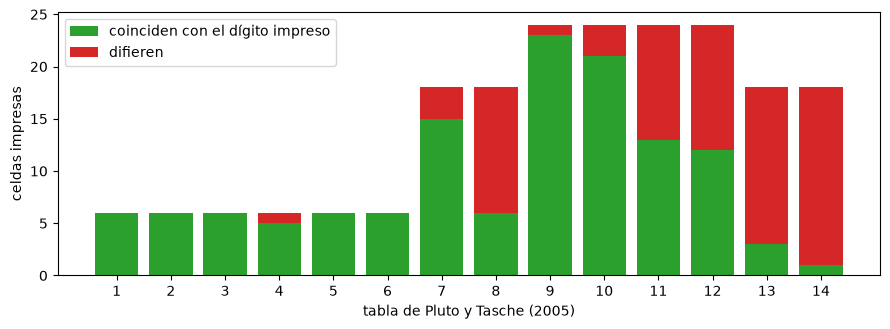

In [10]:
# Dibujar, por tabla, las celdas que coinciden con lo impreso y las que no
counts = [len(gs) for gs in per_table]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(1, 15), agree, color="tab:green", label="coinciden con el dígito impreso")
ax.bar(range(1, 15), [c - a for c, a in zip(counts, agree)], bottom=agree, color="tab:red", label="difieren")
ax.set_xticks(range(1, 15))
ax.set_xlabel("tabla de Pluto y Tasche (2005)")
ax.set_ylabel("celdas impresas")
ax.legend()
fig.tight_layout()
plt.show()

De las 204 celdas impresas el motor reproduce 129 hasta el dígito impreso. Sesenta difieren en una unidad del último dígito impreso, lo que explica un redondeo de la aritmética del propio artículo, y 15 en más: la Tabla 11 al 75% y 95%, las Tablas 13 y 14 de varios años y una celda de la Tabla 12 (B al 99,9%, impreso 9,54 frente a 9,44). Las notas versionadas nombran los grupos. En la Tabla 4 el 0,65% del artículo es la cota al 76,3%, no al 75%, donde la cota exacta es 0,638%, y la Tabla 11 escala con ese 0,65%. Toda celda impresa de la Tabla 8 queda en o sobre la cota exacta. Las tablas de varios años vienen de un Monte Carlo que el motor verifica con una cuadratura determinista, con lo impreso por encima. En 68 de las 75 celdas que difieren lo impreso es lo mayor. Un recálculo que no reproduce un impreso se informa con su celda, no se ajusta.

### Paso 6: lo que dice una verdad conocida

Los tres archivos `ldp-sim` dan la misma cartera en años generados donde las PD verdaderas se conocen: 0,05%, 0,10% y 0,20% con una correlación de 12%, en un año sin incumplimientos, con uno y con tres. Siguen dos lecturas. La celda siguiente aplica el motor a cada año generado y pone la cota al 90% junto a la verdad, y lee del estudio versionado de 20.000 años generados la cobertura de la cota (la fracción de años en que es al menos la PD verdadera) del grado B y la razón mediana entre la cota y la verdad.

In [11]:
# La cota al 90% de cada año generado junto a las PD verdaderas, y la cobertura versionada del grado B
truth = np.array(sims[0]["outputs"]["true_pd"])
print("PD verdaderas:", [f"{100 * v:.2f}%" for v in truth],
      "| años generados en el estudio:", sims[0]["outputs"]["known_truth"]["years"])
for k, doc in sims.items():
    d = tuple(doc["outputs"]["defaults"])
    pds = ld.most_prudent_pd(N, d, 0.9)["pd"]
    print("año con incumplimientos", d, "| cota al 90%:", [f"{100 * v:.3f}%" for v in pds],
          "| cota / verdad:", [round(float(v), 1) for v in pds / truth])
cover = sims[0]["outputs"]["known_truth"]["coverage"]
levels = [r["gamma"] for r in cover["independent"]["B"]]
print("grado B: cobertura, luego cota mediana / PD verdadera")
print(f"{'nivel':>7s}" + "".join(f"{kind:>16s}" for kind in cover))
for i, lv in enumerate(levels):
    print(f"{lv:7.2f}" + "".join(f"{cover[kind]['B'][i]['coverage']:16.4f}" for kind in cover))
for i, lv in enumerate(levels):
    print(f"{lv:7.2f}" + "".join(f"{cover[kind]['B'][i]['ratio_median']:16.2f}" for kind in cover))

PD verdaderas: ['0.05%', '0.10%', '0.20%'] | años generados en el estudio: 20000
año con incumplimientos (0, 0, 0) | cota al 90%: ['0.287%', '0.328%', '0.765%'] | cota / verdad: [5.7, 3.3, 3.8]
año con incumplimientos (0, 0, 1) | cota al 90%: ['0.485%', '0.555%', '1.290%'] | cota / verdad: [9.7, 5.5, 6.5]
año con incumplimientos (0, 0, 3) | cota al 90%: ['0.833%', '0.952%', '2.213%'] | cota / verdad: [16.7, 9.5, 11.1]
grado B: cobertura, luego cota mediana / PD verdadera
  nivel     independent      correlated          scaledscaled_correlated
   0.50          0.4541          1.0000          0.4645          1.0000
   0.75          1.0000          1.0000          1.0000          1.0000
   0.90          1.0000          1.0000          1.0000          1.0000
   0.95          1.0000          1.0000          1.0000          1.0000
   0.99          1.0000          1.0000          1.0000          1.0000
   0.50            0.99            1.73            0.58            1.09
   0.75            

La celda siguiente dibuja la cobertura del grado B para los cuatro tipos de cota, y la razón mediana entre la cota y la PD verdadera.

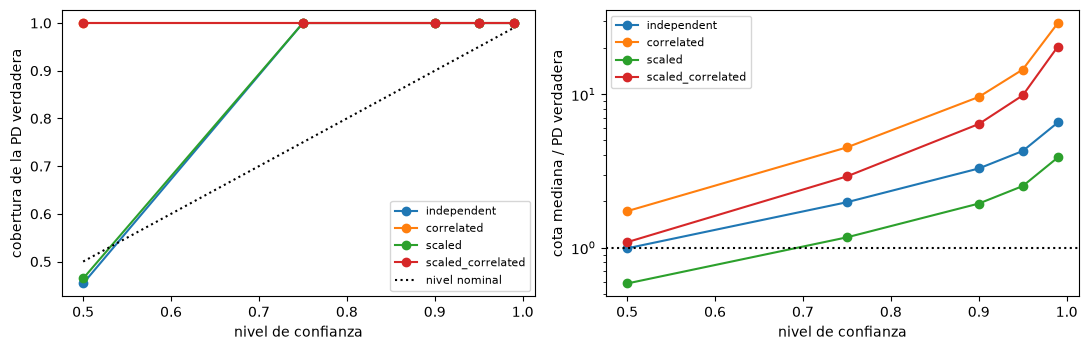

In [12]:
# Dibujar la cobertura del grado B (izquierda) y la cota mediana sobre la PD verdadera (derecha), por nivel de confianza
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
for kind in cover:
    left.plot(levels, [r["coverage"] for r in cover[kind]["B"]], marker="o", label=kind)
    right.plot(levels, [r["ratio_median"] for r in cover[kind]["B"]], marker="o", label=kind)
left.plot(levels, levels, color="black", linestyle=":", label="nivel nominal")
right.axhline(1.0, color="black", linestyle=":")
right.set_yscale("log")
left.set_ylabel("cobertura de la PD verdadera")
right.set_ylabel("cota mediana / PD verdadera")
for ax in (left, right):
    ax.set_xlabel("nivel de confianza")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La cota independiente del grado B cubre la PD verdadera en el 45,4% de los años generados al 50% y en todos los años desde 75% en adelante, con una cota mediana de 0,99 veces la verdad al 50% y 6,56 veces al 99%. La estimación escalada cubre el 46,5% al 50%, porque el 53,5% de los años generados no tiene ningún incumplimiento y la estimación escalada no tiene entonces nada que escalar; las cotas correlacionadas cubren todo desde 50% en adelante, 1,73 veces la verdad al 50% y 29,2 veces al 99%. Las cotas son conservadoras por construcción, y las escaladas ceden cobertura a cambio de un nivel más cercano. La figura muestra el precio de la prudencia en unidades de la verdad, que es cuánto más allá de la PD verdadera se le pide llevar la cifra al validador.

### Paso 7: las PD del experto, y lo que cuestan las cotas en capital

El ejemplo tiene un experto hipotético que dice 0,03%, 0,05% y 0,10%. El artefacto versiona las pruebas de esas PD contra los datos: la prueba de Jeffreys por grado y para la cartera, la prueba binomial y la prueba binomial con correlación de activos. Las cotas son insumos del capital, así que la segunda celda siguiente recalcula el peso de riesgo IRB promedio (Basilea III corporativo, LGD 45%, vencimiento 2,5, piso de PD 0,05%; https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27) de la cartera ponderada por deudor bajo las PD del experto y bajo las cotas al 75%.

In [13]:
# Leer las pruebas versionadas de las PD del experto
print("calculado con riskvalidation", published["provenance"]["riskvalidation_version"],
      "| instalado", md.version("riskvalidation"))
print(f"{'prueba':22s}{'segmento':>12s}{'p':>10s}{'luz':>8s}")
for t in published["tests"]:
    print(f"{t['test_id']:22s}{str(t['segment']):>12s}{t['p_value']:10.4f}{t['light']:>8s}")

calculado con riskvalidation 1.0.1 | instalado 1.0.1
prueba                    segmento         p     luz
pd.jeffreys                      A    0.1938   green
pd.jeffreys                      B    0.0047     red
pd.jeffreys                      C    0.1035   green
pd.jeffreys              portfolio    0.0062     red
pd.binomial              portfolio    0.0167   amber
pd.binomial_vasicek      portfolio    0.0507   green


La celda siguiente pone precio, en peso de riesgo promedio, a las PD del experto y a las cotas al 75%, independientes, correlacionadas y escaladas.

In [14]:
# Peso de riesgo IRB promedio de la cartera bajo las PD del experto y bajo las cotas al 75%
cfg = out["irb"]
weights_n = np.array(N, dtype=float)
scenarios = {
    "PD del experto (con piso 0,05%)": out["expert_pd"],
    "más prudente al 75%": ld.most_prudent_pd(N, few, 0.75)["pd"],
    "más prudente al 75%, correlación 12%": ld.most_prudent_pd(N, few, 0.75, rho)["pd"],
    "escalada a la cota de la cartera al 75%": ld.most_prudent_pd_scaled(N, few, 0.75, target="upper_bound")["pd"],
}
average = {}
for label, pds in scenarios.items():
    rw = [irb.capital_requirement(cfg["asset_class"], float(p), cfg["lgd"], maturity=cfg["maturity"],
                                  regime=cfg["regime"]).risk_weight for p in pds]
    average[label] = float(np.sum(weights_n * np.array(rw)) / weights_n.sum())
    print(f"{label:68s}{100 * average[label]:8.1f}%")

PD del experto (con piso 0,05%)                                         23.4%
más prudente al 75%                                                     83.8%
más prudente al 75%, correlación 12%                                   108.1%
escalada a la cota de la cartera al 75%                                 77.2%


La celda siguiente dibuja los cuatro pesos de riesgo promedio.

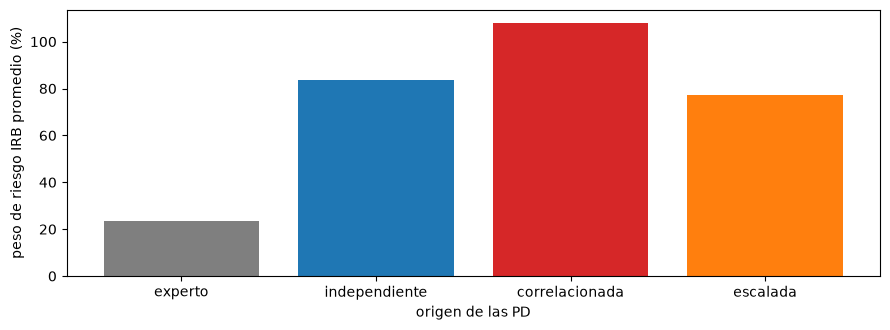

In [15]:
# Dibujar el peso de riesgo IRB promedio bajo las PD del experto y bajo los tres tipos de cota
fig, ax = plt.subplots(figsize=(9, 3.4))
short = ["experto", "independiente", "correlacionada", "escalada"]
ax.bar(short, [100 * v for v in average.values()], color=["tab:gray", "tab:blue", "tab:red", "tab:orange"])
ax.set_xlabel("origen de las PD")
ax.set_ylabel("peso de riesgo IRB promedio (%)")
fig.tight_layout()
plt.show()

Las PD del experto hipotético son rechazadas por la prueba de Jeffreys para el grado B (p = 0,0047, rojo) y para la cartera (p = 0,0062, rojo), ámbar por la prueba binomial (p = 0,0167) y verde una vez que se admite la correlación (p = 0,0507): que las cifras estén equivocadas depende de si los incumplimientos son independientes. En capital la brecha es grande con cualquier prueba. Las PD del experto dan un peso de riesgo promedio de 23,4%, las cotas al 75% 83,8%, las correlacionadas 108,1% y las escaladas 77,2%. El principio de estimación vale decenas de puntos de peso de riesgo, y la figura muestra que el escalamiento, que renuncia a la lectura como cota de confianza, quita solo cerca de una décima del capital adicional que pide la cota cruda.

## Resultados

**Respuesta:** una cartera de bajo incumplimiento puede defender una PD positiva para cada grado, incluso uno sin incumplimientos, como cota superior de confianza sobre el conjunto de ese grado y todos los peores: al 90% los tres incumplimientos en 800 deudores del ejemplo dan 0,8332% para A, 0,9519% para B y 1,2903% para C. La correlación de activos de 12% del artículo las sube a 2,4910%, 2,7617% y 3,1813%, y la prudencia cuesta capital: las PD del experto hipotético dan un peso de riesgo IRB promedio de 23,4%, frente a 83,8% con las cotas al 75%, 108,1% con las correlacionadas y 77,2% con las escaladas. Las PD del experto se rechazan para el grado B (p de Jeffreys = 0,0047) y para la cartera (p = 0,0062), y se aceptan una vez que se admite la correlación (p = 0,0507).

- **Escalamiento.** Escaladas a la cota del mejor grado (la propuesta del artículo) las cotas al 90% son un factor K = 0,7831 de las crudas; escaladas a la tasa de incumplimiento observada de la cartera de 0,3750% el factor es K = 0,3525. En ambos casos el promedio ponderado iguala la meta y se mantiene el orden.
- **Años de observación.** Las cotas a cinco años con correlación de activos de 12% y correlación de factores de 30% de un año a otro son menores que las de un año: al 90%, 0,3241%, 0,3647% y 0,4425% frente a 0,8332%, 0,9519% y 1,2903% para el ejemplo.
- **Las 204 celdas impresas.** El motor reproduce 129 hasta el dígito impreso. Sesenta difieren en una unidad del último dígito impreso y 15 en más, y donde difieren lo impreso está sobre el recálculo en 68 de 75 celdas.
- **Lo que dice una verdad conocida.** La cota independiente del grado B cubre la PD verdadera en el 45,4% de los años generados al 50% y en todos los años desde 75%, con una cota mediana de 6,56 veces la verdad al 99%.

Lo que este notebook no muestra: cómo elige un validador un nivel de confianza (el artículo llama arbitraria la elección y dice que los niveles bajo 95% parecen más apropiados), ni la curva de PD de una cartera calificada (notebooks 05 y 09).

## Resumen

- Con pocos o ningún incumplimiento la PD de un grado es una cota superior de confianza sobre el conjunto de ese grado y todos los peores; la cota es monótona entre grados y positiva incluso sin incumplimientos.
- La correlación de incumplimientos sube la cota varias veces; escalar a una meta de la cartera la baja y renuncia a su lectura como cota; varios años de observación la bajan.
- Las 204 celdas impresas del artículo se recalculan: 129 hasta el dígito, el resto informado con su brecha y la razón que dan las notas versionadas.
- Una cota es conservadora por construcción: sobre una verdad conocida cubre en todos los años desde 75% y es varias veces la PD verdadera.

**Qué probar después.** Cambia el número de incumplimientos del grado A en el Paso 1 de 0 a 1 y mira moverse las tres cotas; luego lee el notebook 07.

## Referencias

- Pluto, K. y Tasche, D. (2005), Estimating probabilities of default for low default portfolios, en Engelmann y Rauhmeier (eds), The Basel II Risk Parameters, Springer; arXiv cond-mat/0411699, secciones 2 a 6, Tablas 1 a 14. https://arxiv.org/abs/cond-mat/0411699
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), para las cotas de Clopper-Pearson y de Jeffreys. https://doi.org/10.1214/ss/1009213286
- BCBS, Basel Framework, CRE32, enfoque IRB: cálculo de activos ponderados por riesgo. https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- Vasicek, O. (2002), Loan portfolio value, Risk, December 2002, 160-162, para el modelo de un factor.